<div class='alert alert-block alert-success'>
<h1 align='center'>None Linear Regression(Polynomial)</h1>
<h2 align='center'>Fuel Dataset</h2>
</div>

# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load Dataset

In [2]:
Train_df=pd.read_csv(r'auto-train-preprocessed.csv')
Test_df=pd.read_csv(r'auto-test-preprocessed.csv')
Train_df.head()

,HorsePower,MPG
0,0.038043,0.638298
1,0.646739,0.106383
2,0.157609,0.398936
3,0.239130,0.239362
4,0.728261,0.186170


# Feature & Label spliting

In [3]:
x_train=Train_df.iloc[:,0]
y_train=Train_df.iloc[:,1]

x_test=Test_df.iloc[:,0]
y_test=Test_df.iloc[:,1]

# EDA

In [4]:
print(Train_df.info())
print(f'{Train_df.describe()}\n')

<class 'pandas.DataFrame'>
RangeIndex: 352 entries, 0 to 351
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   HorsePower  352 non-null    float64
 1   MPG         352 non-null    float64
dtypes: float64(2)
memory usage: 5.6 KB
None
       HorsePower         MPG
count  352.000000  352.000000
mean     0.311512    0.385434
std      0.200227    0.204968
min      0.000000    0.000000
25%      0.161685    0.226064
50%      0.250000    0.372340
75%      0.429348    0.531915
max      0.972826    1.000000



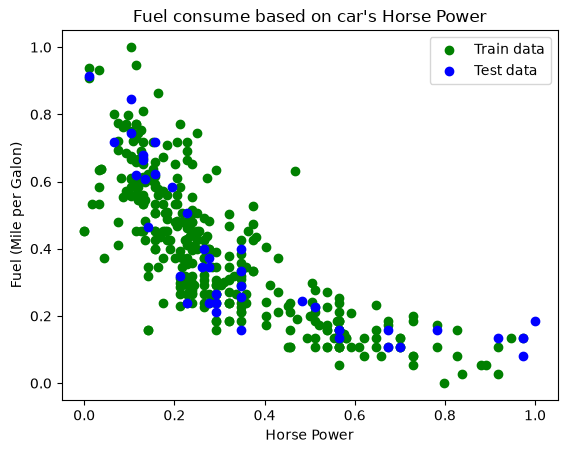

In [5]:
plt.title("Fuel consume based on car's Horse Power")
plt.xlabel('Horse Power')
plt.ylabel('Fuel (Mile per Galon)')
plt.scatter(x_train, y_train, c='green', label='Train data' )
plt.scatter(x_test, y_test, c='blue', label='Test data' )
plt.legend()
plt.show()

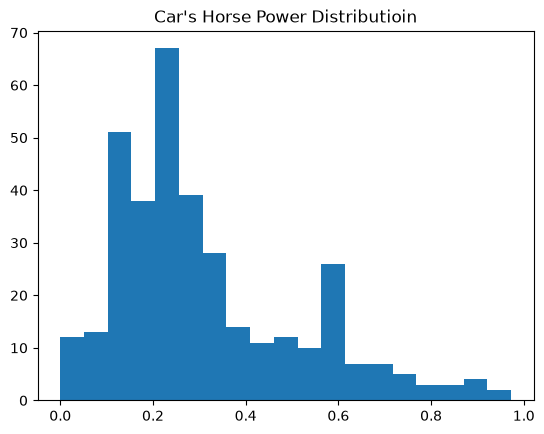

In [6]:
plt.title("Car's Horse Power Distributioin")
plt.hist(x=x_train, bins=19)
plt.show()

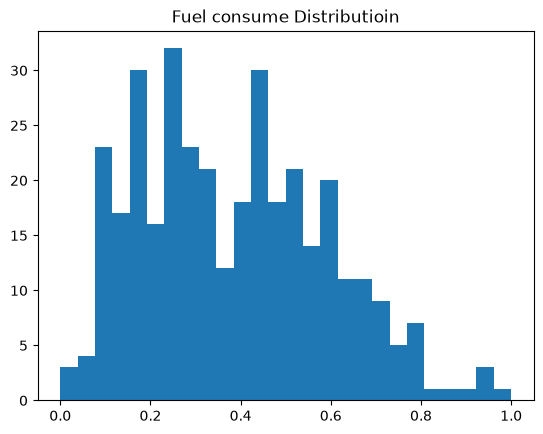

In [7]:
plt.title("Fuel consume Distributioin")
plt.hist(x=y_train, bins=26)
plt.show()

# Required functions

In [8]:
def fi(arr,d):
    arr=arr.reshape(-1,1)
    powers=np.arange(d+1).reshape(1,-1)
    x_poly=arr**powers
    return x_poly

In [9]:
def predict(fi_x , w):
    return fi_x @ w.T

In [10]:
def gradient_descent(fi_m, y_pre, y):
    error=y_pre-y
    return 2*(fi_m.T @ error)/len(error)

In [11]:
def MSE(y_pre, y):
    error=y_pre-y
    return np.mean(error**2)

In [12]:
def MAE(y_pre, y):
    error=y_pre-y
    return np.mean(np.abs(error))

In [13]:
def eval(d, w, x, y):
    x=x.to_numpy().reshape(-1,1)
    fi_x_test=fi(x, d)
    y_pre=predict(fi_x_test, w)
    return round(MSE(y_pre , y),4) , round(MAE (y_pre, y),4)

# Optimization loop

In [14]:
def polynomial_opt_loop(d, epoch_num,x , y ,learning_rate):
    x=x.to_numpy().reshape(-1,1)
    np.random.seed(10)
    w=np.random.rand(d+1)
    fi_x=fi(x, d)

    loss_hist=[]
    w_hist=np.array([w])

    for epoch in range(epoch_num):
        y_predict=predict(fi_x, w)
        w-=learning_rate*gradient_descent(fi_x, y_predict, y)
        loss=MSE(y_predict, y)

        loss_hist.append(loss)
        w_hist=np.vstack((w_hist, w))

    idx=np.argmin(loss_hist)
    best_w=w_hist[idx+1]
    return loss_hist ,best_w  #loss_hist[idx],

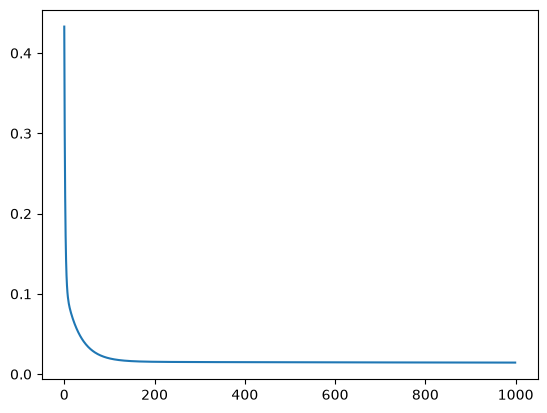

In [15]:
loss_for_3d, w_for_3d=polynomial_opt_loop(d=3, 
                                        epoch_num=1000, 
                                        x=x_train, 
                                        y=y_train, 
                                        learning_rate=0.1)
plt.plot(range(len(loss_for_3d)), loss_for_3d)

In [16]:
epoch_num=1000
learning_rate=0.1
w_for_2d=polynomial_opt_loop(2, epoch_num, x_train, y_train, learning_rate)[1]
w_for_3d=polynomial_opt_loop(3, epoch_num, x_train , y_train, learning_rate)[1]
w_for_4d=polynomial_opt_loop(4,  epoch_num, x_train, y_train, learning_rate)[1]
w_for_5d=polynomial_opt_loop(5,  epoch_num, x_train, y_train, learning_rate)[1]

print(w_for_2d)
print(w_for_3d)
print(w_for_4d)
print(w_for_5d)

[ 0.65492856 -0.96653514  0.22956999]
[ 0.67804684 -1.04605281  0.01295153  0.41359902]
[ 0.68295707 -1.04798725 -0.04574392  0.32715732  0.21270003]
[ 0.68454601 -1.05440373 -0.04843369  0.32773043  0.21525562  0.01790315]


# Evaluation metrics

In [17]:
MSE_2D, MAE_2D= eval(2, w_for_2d, x_test, y_test)
MSE_3D, MAE_3D= eval(3, w_for_3d, x_test, y_test)
MSE_4D, MAE_4D= eval(4, w_for_4d, x_test, y_test)
MSE_5D, MAE_5D= eval(5, w_for_5d, x_test, y_test)

In [18]:
eval_df=pd.DataFrame({'MSE':[MSE_2D, MSE_3D, MSE_4D, MSE_5D],
                     'MAE':[MAE_2D, MAE_3D, MAE_4D, MAE_5D,]}, 
                     index=['polynomial 2D',
                            'polynomial 3D',
                            'polynomial 4D',
                            'polynomial 5D'])
print(eval_df)

                  MSE     MAE
polynomial 2D  0.0184  0.1115
polynomial 3D  0.0135  0.0939
polynomial 4D  0.0126  0.0891
polynomial 5D  0.0124  0.0883


# Model Visualization

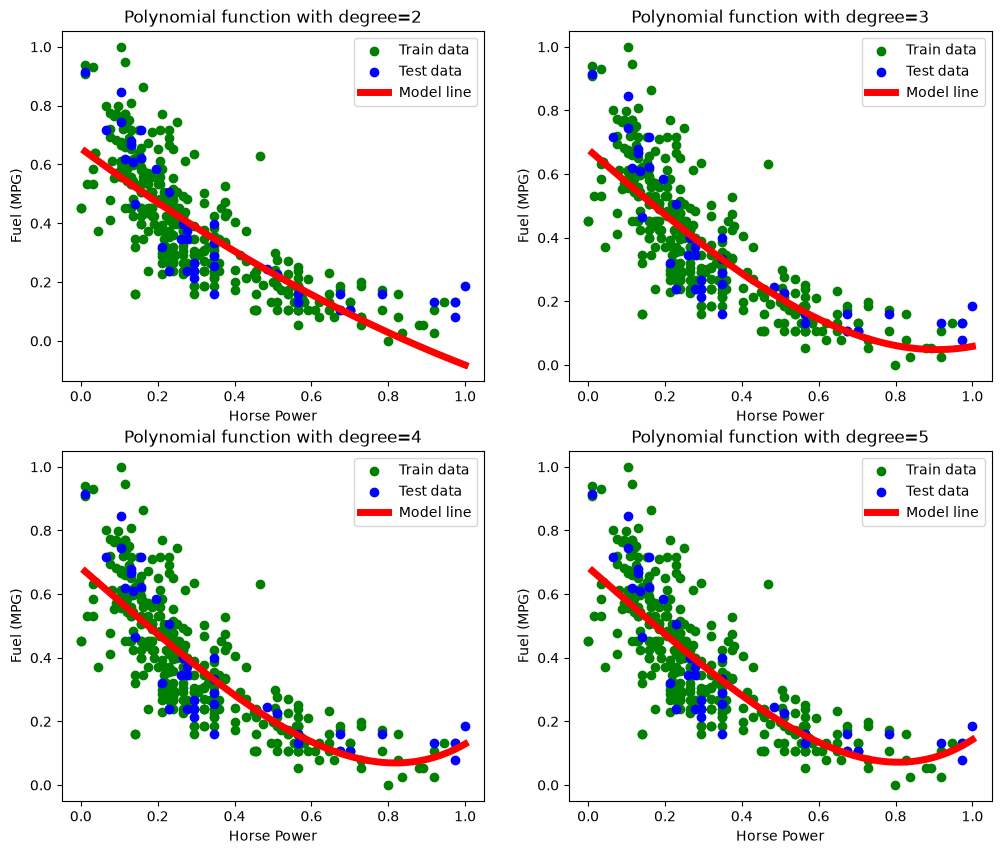

In [21]:
def model_plot(r,c, d, w, x_tr, y_tr, x_te, y_te, x_lins):
    fi_p=fi(x_lin,d)
    y_pred=predict(fi_p, w)
    ax[r][c].set_title(f'Polynomial function with degree={d}')
    ax[r][c].set_xlabel('Horse Power')
    ax[r][c].set_ylabel('Fuel (MPG)')
    ax[r][c].scatter(x_tr, y_tr, c='green', label='Train data')
    ax[r][c].scatter(x_te, y_te, c='blue' , label='Test data')
    ax[r][c].plot(x_lins, y_pred ,c='red', linewidth=5, label='Model line')
    ax[r][c].legend()

x_min, x_max=x_test.min(), x_test.max()
x_lin=np.linspace(x_min, x_max, 400)

fig, ax=plt.subplots(2,2, figsize=(12,10))
model_plot(0,0, 2, w_for_2d, x_train, y_train, x_test, y_test, x_lin)
model_plot(0,1, 3, w_for_3d, x_train, y_train, x_test, y_test, x_lin)
model_plot(1,0, 4, w_for_4d, x_train, y_train, x_test, y_test, x_lin)
model_plot(1,1, 5, w_for_5d, x_train, y_train, x_test, y_test, x_lin)
